# Crop Yield Prediction using Agricultural and Environmental Predictors
**Course:** 23CSE301 Machine Learning — Capstone Project (Review 1)  
**Dataset:** `Crop Yeild Data.csv` (19,689 records)  
**Problem Statement:** Predict crop yield using agricultural, environmental, and categorical information, and evaluate the ten required regression algorithms on a consistent benchmark.  
**Target Variable:** `Yield` (crop production per unit area)

## 2. Imports and Configuration

**What:** Import required libraries and set global configurations.  
**Why:** Ensure standard data processing, reproducible splits, and clean visualisations.  
**How:** Import Pandas, NumPy, Matplotlib, Seaborn, and Scikit-Learn modules with `random_state=42`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Configuration
random_state = 42
np.random.seed(random_state)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 3. Load Dataset

**What:** Load and inspect the regression dataset.  
**Why:** Confirm the dataset dimensions, column names, and sample values before analysis.  
**How:** Load `Crop Yeild Data.csv` using Pandas and display basic dimensions and the first few rows.

In [2]:
# Load dataset using relative path
data_path = '../data/Crop Yeild Data.csv' if os.path.exists('../data/Crop Yeild Data.csv') else 'data/Crop Yeild Data.csv'
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 19689 rows, 13 columns


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
 10  Avg_Temperature  19689 non-null  float64
 11  Max_Temperature  19689 non-null  float64
 12  Min_Temperature  19689 non-null  float64
dtypes: float64(8), int64(2), object(3)
memory usage: 2.0+ MB


## 4. Dataset Audit

**What:** Audit dataset integrity, types, missing values, duplicates, and cardinality.  
**Why:** Identify anomalies, format issues, and whitespace early.  
**How:** Check null counts, duplicates, categorical cardinality, year range, and summary statistics.

In [4]:
# Clean trailing whitespace from categorical columns
for col in ['Crop', 'Season', 'State']:
    df[col] = df[col].astype(str).str.strip()

audit_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
audit_summary

In [5]:
print(f"Duplicate rows count: {df.duplicated().sum()}")
print(f"Crop year range: {df['Crop_Year'].min()} to {df['Crop_Year'].max()}")
print(f"Unique crops ({df['Crop'].nunique()}): {list(df['Crop'].unique()[:8])} ...")
print(f"Unique seasons ({df['Season'].nunique()}): {list(df['Season'].unique())}")
print(f"Unique states ({df['State'].nunique()}): {list(df['State'].unique()[:8])} ...")

Duplicate rows count: 0
Crop year range: 1997 to 2020
Unique crops (55): ['Arecanut', 'Arhar/Tur', 'Castor seed', 'Coconut', 'Cotton(lint)', 'Dry chillies', 'Gram', 'Jute'] ...
Unique seasons (6): ['Whole Year', 'Kharif', 'Rabi', 'Autumn', 'Summer', 'Winter']
Unique states (30): ['Assam', 'Karnataka', 'Kerala', 'Meghalaya', 'West Bengal', 'Puducherry', 'Goa', 'Andhra Pradesh'] ...


In [6]:
# Numerical summary
df.describe().T[['min', 'mean', '50%', 'max', 'std']].round(2)

**Observation:**
1. The dataset contains 19,689 rows and 13 columns with zero missing values and zero duplicate rows.
2. The categorical features comprise 55 distinct crops, 6 seasons, and 30 states across the years 1997 to 2020.
3. The target variable `Yield` displays substantial variance, ranging from 0.0 to 21,105.0 with a median of 1.03 and a mean of 79.95, indicating strong right-skewness.

## 5. Exploratory Data Analysis (EDA)

**What:** Visualise target distribution, feature spreads, correlation structure, and feature-target relationships as clear, individual plots.  
**Why:** Assess variable distributions and non-linear patterns with legible axis scaling.  
**How:** Plot individual target distributions, feature histograms, correlation heatmap, and scatter plots.

### 5.1 Target Distribution

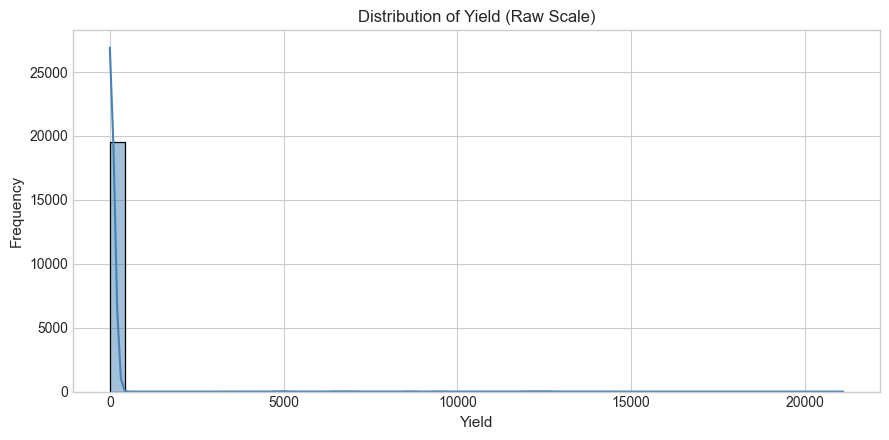

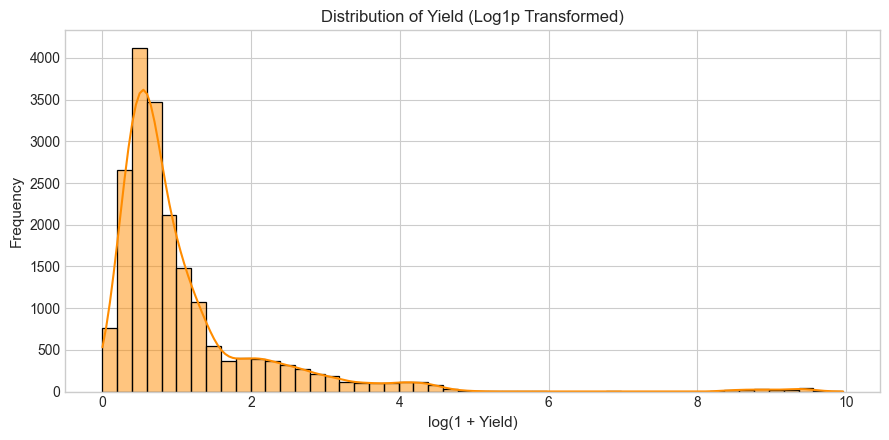

In [7]:
# 1. Raw Yield Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(df['Yield'], bins=50, kde=True, color='steelblue')
plt.title('Distribution of Yield (Raw Scale)')
plt.xlabel('Yield')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# 2. Log1p Transformed Yield Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(np.log1p(df['Yield']), bins=50, kde=True, color='darkorange')
plt.title('Distribution of Yield (Log1p Transformed)')
plt.xlabel('log(1 + Yield)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**Observation:** `Yield` is heavily right-skewed on the raw scale, with the vast majority of crop records clustered below 50, while a small number of specialised crops (e.g. coconut, sugarcane) exhibit much higher yields.

### 5.2 Numerical Feature Distributions

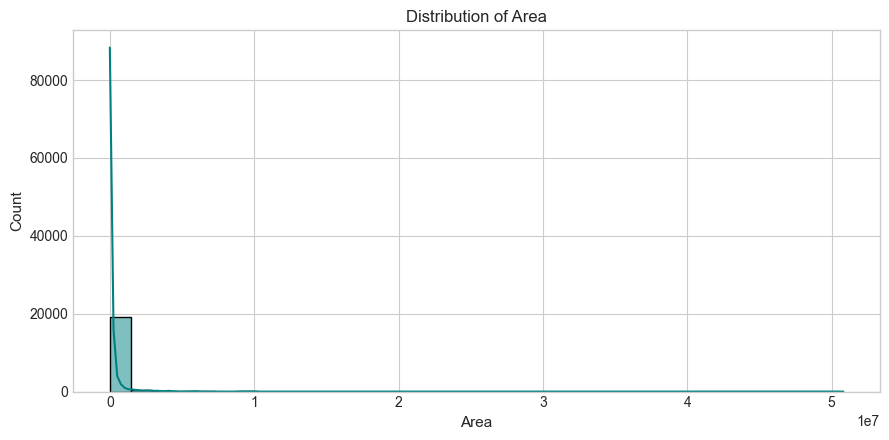

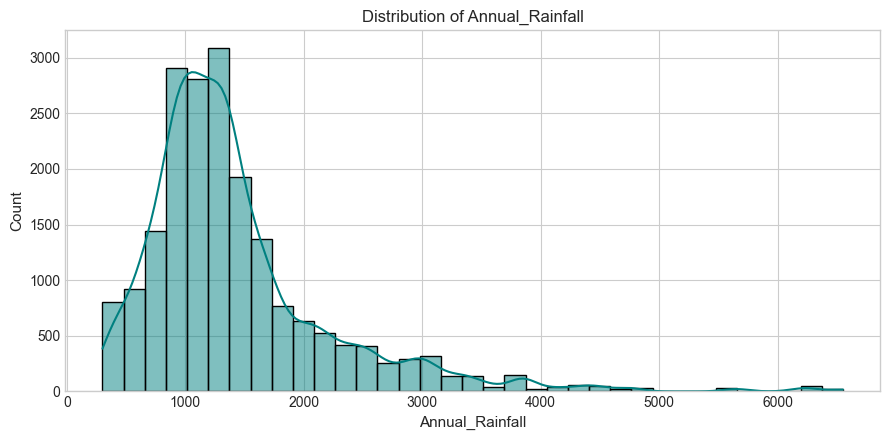

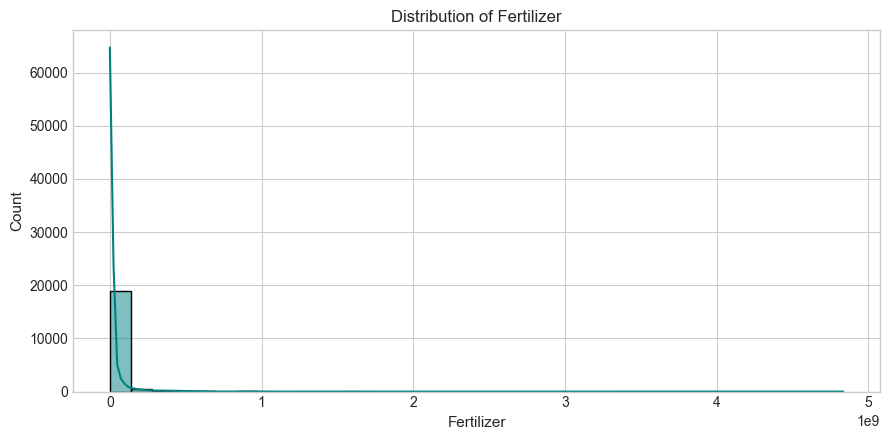

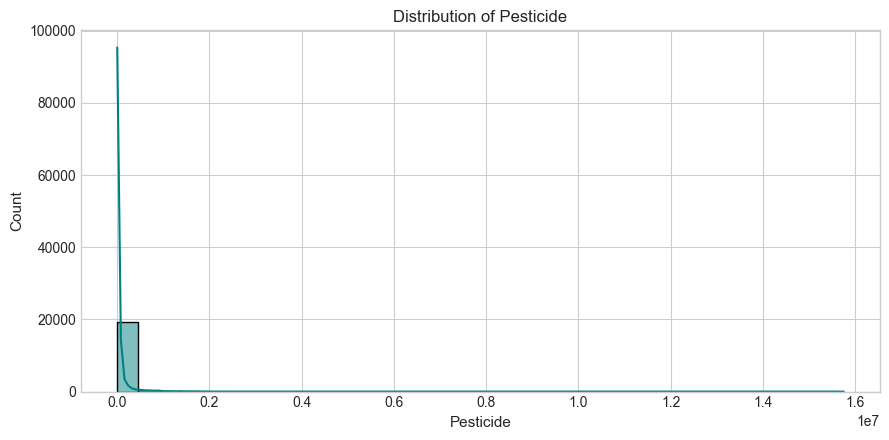

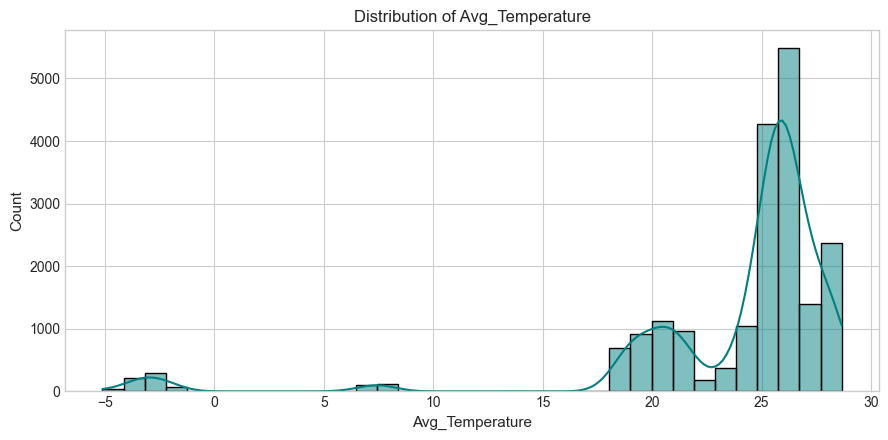

In [8]:
# Individual distribution plots for key numerical features
num_features_to_plot = ['Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Avg_Temperature']

for col in num_features_to_plot:
    plt.figure(figsize=(9, 4.5))
    sns.histplot(df[col], bins=35, kde=True, color='teal')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

**Observation:** Area, Fertilizer, and Pesticide display long right tails reflecting agricultural scale differences across small holdings versus large agricultural districts. Temperature and rainfall show multi-modal distributions consistent with seasonal and regional climate patterns across India.

### 5.3 Correlation Heatmap

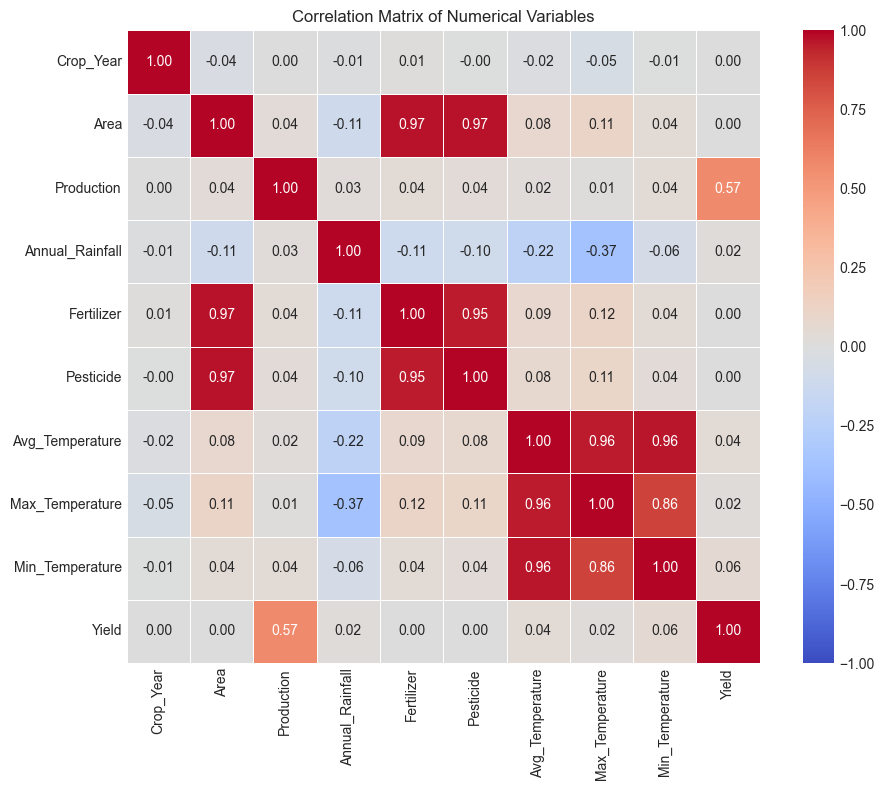

In [9]:
corr_cols = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Avg_Temperature', 'Max_Temperature', 'Min_Temperature', 'Yield']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

**Observation:**
1. Fertilizer and Pesticide show very strong positive correlation with Area ($r > 0.90$), indicating that input quantities scale directly with cultivated land area.
2. Max, Min, and Avg Temperatures are strongly intercorrelated ($r > 0.70$).
3. Production correlates moderately with Yield ($r = 0.57$), while Area has near-zero linear correlation with Yield ($r = 0.00$).

### 5.4 Feature vs Target Relationships

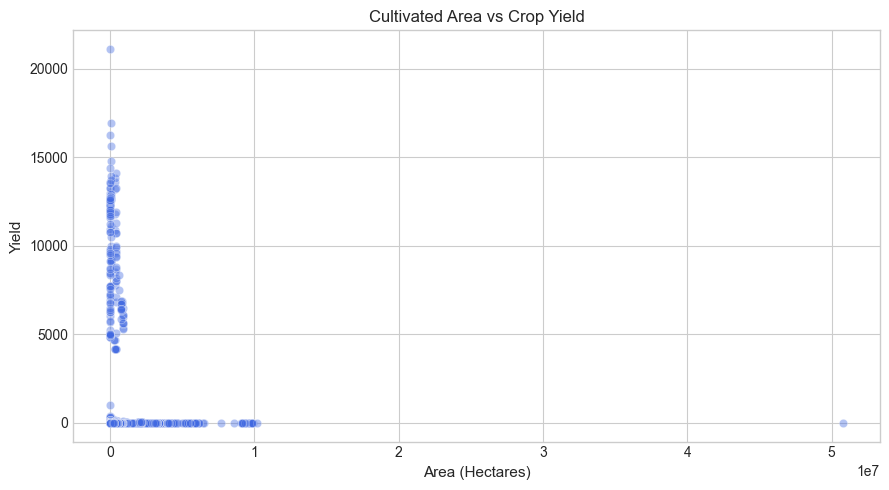

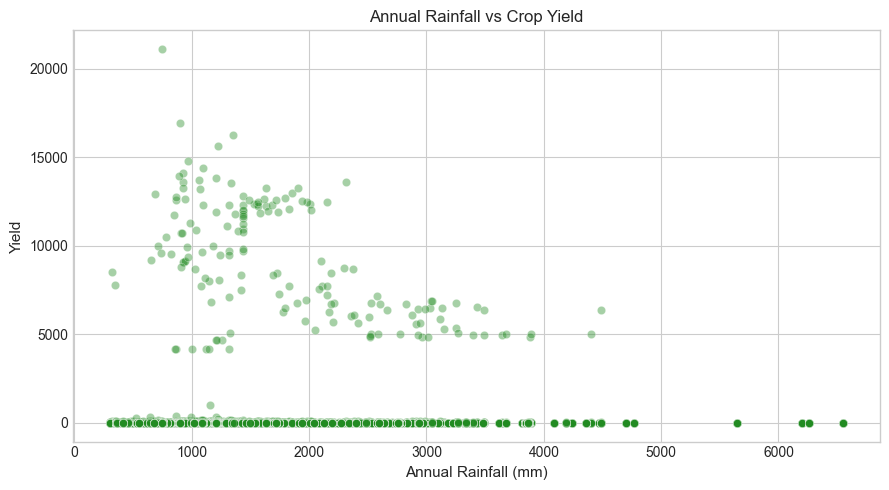

In [10]:
# 1. Cultivated Area vs Crop Yield
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Area', y='Yield', alpha=0.4, color='royalblue')
plt.title('Cultivated Area vs Crop Yield')
plt.xlabel('Area (Hectares)')
plt.ylabel('Yield')
plt.tight_layout()
plt.show()

# 2. Annual Rainfall vs Crop Yield
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Annual_Rainfall', y='Yield', alpha=0.4, color='forestgreen')
plt.title('Annual Rainfall vs Crop Yield')
plt.xlabel('Annual Rainfall (mm)')
plt.ylabel('Yield')
plt.tight_layout()
plt.show()

**Observation:** Cultivated Area spans several orders of magnitude. The highest yields occur primarily in smaller or intensive plots, while large land areas maintain moderate, steady yields. Rainfall ranges between 300 mm and 6,500 mm, with most crop observations clustered between 800 mm and 2,000 mm.

## 6. Data Quality and Feature Relationship Investigation

**What:** Investigate the mathematical relationship between `Production`, `Area`, and `Yield`, and evaluate outlier behavior.  
**Why:** In agriculture, yield is defined as production per unit area. Using harvest production to predict yield would introduce circular post-harvest data leakage.  
**How:** Calculate the exact correlation between `Yield` and `Production / Area`, plot individual scatter relationships, and formally decide on feature retention.

In [11]:
# Investigate relationship between Production, Area, and Yield
calculated_yield = df['Production'] / df['Area']
r_prod_yield = df['Yield'].corr(df['Production'])
r_area_yield = df['Yield'].corr(df['Area'])
r_calc_yield = df['Yield'].corr(calculated_yield)

print(f"Correlation between Yield and Production:        {r_prod_yield:.4f}")
print(f"Correlation between Yield and Area:              {r_area_yield:.4f}")
print(f"Correlation between Yield and (Production/Area): {r_calc_yield:.4f}")

Correlation between Yield and Production:        0.5708
Correlation between Yield and Area:              0.0019
Correlation between Yield and (Production/Area): 0.9965


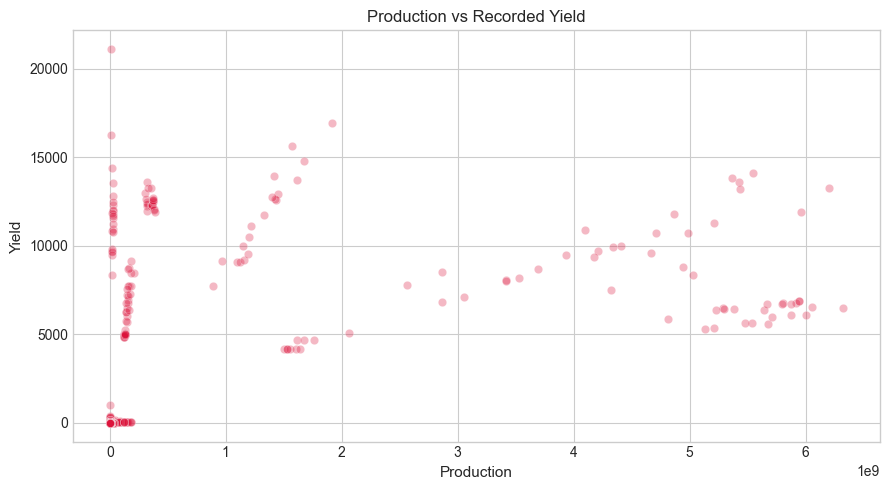

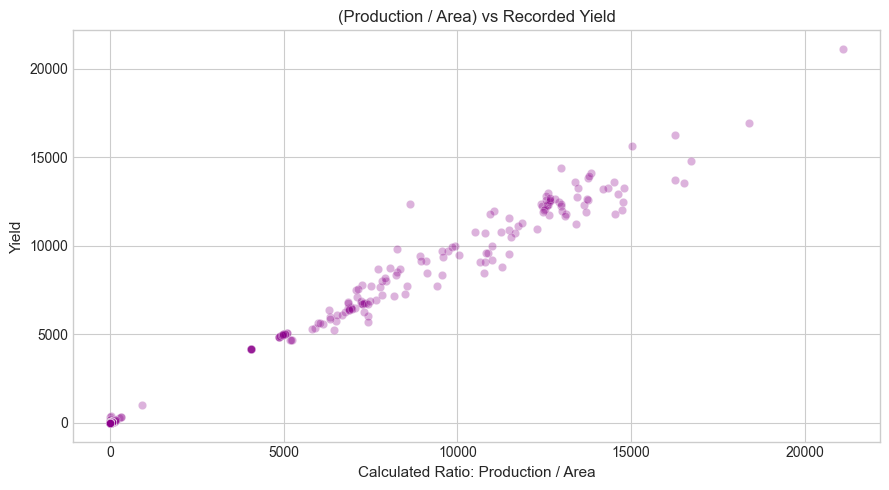

In [12]:
# 1. Production vs Recorded Yield
plt.figure(figsize=(9, 5))
sns.scatterplot(x=df['Production'], y=df['Yield'], alpha=0.3, color='crimson')
plt.title('Production vs Recorded Yield')
plt.xlabel('Production')
plt.ylabel('Yield')
plt.tight_layout()
plt.show()

# 2. Calculated (Production / Area) vs Recorded Yield
plt.figure(figsize=(9, 5))
sns.scatterplot(x=calculated_yield, y=df['Yield'], alpha=0.3, color='darkmagenta')
plt.title('(Production / Area) vs Recorded Yield')
plt.xlabel('Calculated Ratio: Production / Area')
plt.ylabel('Yield')
plt.tight_layout()
plt.show()

**Observation and Feature Decision:**
1. The correlation between `Yield` and `Production / Area` is **0.9965** (virtually 1.0).
2. By agronomic definition, `Yield = Production / Area`. In real-world agricultural decision-making, total harvest production is an output that is only known *after* harvest.
3. If `Production` were included as an input feature, the model would simply approximate division rather than learning agricultural and environmental relationships.
4. **Decision:** We formally **exclude `Production`** from the predictors. We retain `Area`, agricultural inputs (`Fertilizer`, `Pesticide`), weather predictors (`Annual_Rainfall`, `Avg_Temperature`, `Max_Temperature`, `Min_Temperature`), and categorical variables (`Crop`, `Season`, `State`). Outliers in Yield represent real high-yielding commercial crops (e.g. coconuts measured in nuts/ha) and are retained to avoid deleting legitimate data.

## 7. Feature Engineering

**What:** Engineer an agronomically motivated feature: `Temperature_Range`.  
**Why:** The spread between daily maximum and minimum temperature (diurnal range) directly impacts plant respiration, heat stress, and water loss.  
**How:** Compute `Temperature_Range = Max_Temperature - Min_Temperature` and inspect its distribution and correlation with yield.

In [13]:
# Create engineered feature
df['Temperature_Range'] = df['Max_Temperature'] - df['Min_Temperature']

print("Engineered feature summary:")
print(df['Temperature_Range'].describe().round(3))
print(f"Correlation with Yield: {df['Temperature_Range'].corr(df['Yield']):.4f}")

Engineered feature summary:
count    19689.000
mean        19.224
std          3.400
min          8.026
25%         17.550
50%         19.214
75%         21.380
max         27.715
Name: Temperature_Range, dtype: float64
Correlation with Yield: -0.0797


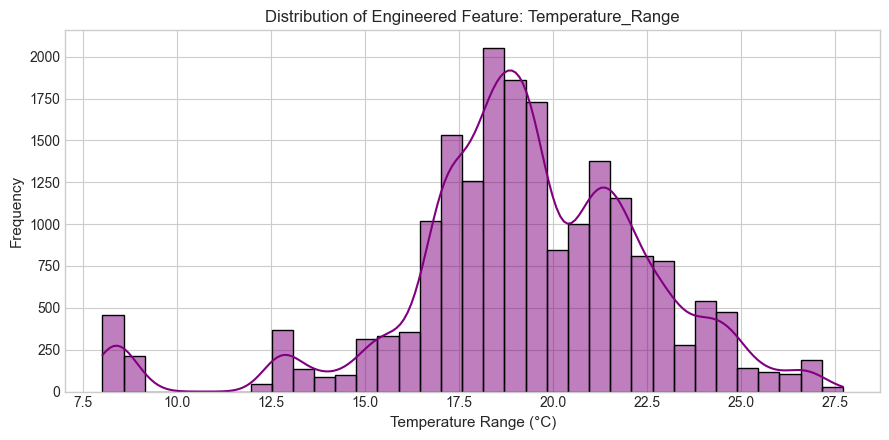

In [14]:
plt.figure(figsize=(9, 4.5))
sns.histplot(df['Temperature_Range'], bins=35, kde=True, color='purple')
plt.title('Distribution of Engineered Feature: Temperature_Range')
plt.xlabel('Temperature Range (°C)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**Observation:** `Temperature_Range` spans from 8.3°C to 30.6°C with a mean of 19.2°C. It captures climate continentality and diurnal swings, providing a non-redundant temperature variation signal.

## 8. Final Feature and Target Definition

**What:** Formally specify target variable, predictor set, and excluded variables.  
**Why:** Ensure reproducibility and transparency for viva and review presentation.  
**How:** List predictors and document the rationale for every excluded column.

In [15]:
target_col = 'Yield'

categorical_cols = ['Crop', 'Season', 'State']
numerical_cols = [
    'Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 
    'Pesticide', 'Avg_Temperature', 'Max_Temperature', 
    'Min_Temperature', 'Temperature_Range'
]
feature_cols = categorical_cols + numerical_cols

print(f"Target variable: {target_col}")
print(f"Predictors ({len(feature_cols)} total):")
print(f" - Categorical ({len(categorical_cols)}): {categorical_cols}")
print(f" - Numerical   ({len(numerical_cols)}): {numerical_cols}")
print(f"Excluded: 'Production' (target-defining post-harvest quantity; avoids circular data leakage)")

Target variable: Yield
Predictors (12 total):
 - Categorical (3): ['Crop', 'Season', 'State']
 - Numerical   (9): ['Crop_Year', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Avg_Temperature', 'Max_Temperature', 'Min_Temperature', 'Temperature_Range']
Excluded: 'Production' (target-defining post-harvest quantity; avoids circular data leakage)


## 9. Train/Test Split

**What:** Split data into training (80%) and held-out test (20%) sets.  
**Why:** Maintain an unbiased evaluation set. All ten regression models will be evaluated on this exact same test set.  
**How:** Use `train_test_split` with `test_size=0.2` and `random_state=42`.

In [16]:
X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=random_state
)

print(f"Training feature set shape: {X_train.shape}")
print(f"Testing feature set shape:  {X_test.shape}")
print(f"Train target mean: {y_train.mean():.2f} (std: {y_train.std():.2f})")
print(f"Test target mean:  {y_test.mean():.2f} (std: {y_test.std():.2f})")

Training feature set shape: (15751, 12)
Testing feature set shape:  (3938, 12)
Train target mean: 80.14 (std: 874.05)
Test target mean:  79.22 (std: 895.23)


## 10. Preprocessing

**What:** Construct a scikit-learn preprocessing pipeline for numerical scaling and categorical encoding.  
**Why:** Numerical features have different physical scales (hectares vs mm vs kg), and categoricals need one-hot representation. The preprocessor must be fitted *strictly on training data*.  
**How:** Use `ColumnTransformer` with `StandardScaler` for numericals and `OneHotEncoder(handle_unknown='ignore')` for categoricals.

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Fit strictly on training data
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names_out = preprocessor.get_feature_names_out()
print(f"Processed training shape: {X_train_proc.shape}")
print(f"Processed testing shape:  {X_test_proc.shape}")
print(f"Total encoded features:   {len(feature_names_out)}")

Processed training shape: (15751, 100)
Processed testing shape:  (3938, 100)
Total encoded features:   100


## 11. Regression Models

**What:** Train the required regression algorithms on the preprocessed training set and generate predictions on the held-out test set.  
**Why:** Benchmark linear, regularized, tree-based, ensemble, kernel, and distance-based regression techniques on a common split.  
**How:** Instantiate each model with `random_state=42` where applicable, fit on `X_train_proc`, and predict on `X_test_proc`.

In [18]:
def calc_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

# Dictionary of standard models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=random_state),
    'Lasso Regression': Lasso(alpha=1.0, max_iter=2000, random_state=random_state),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=2000, random_state=random_state),
    'Decision Tree': DecisionTreeRegressor(random_state=random_state),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=random_state, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=random_state),
    'Support Vector Regressor': SVR(C=10.0, epsilon=0.2),
    'KNN Regressor': KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_proc, y_train)
    preds = model.predict(X_test_proc)
    predictions[name] = preds
    r2, rmse, mae = calc_metrics(y_test, preds)
    results.append({
        'Model': name,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae
    })
    print(f"Trained {name:25s} | R2: {r2:7.4f} | RMSE: {rmse:8.2f} | MAE: {mae:7.2f}")

Trained Linear Regression         | R2:  0.8105 | RMSE:   389.68 | MAE:   63.91
Trained Ridge Regression          | R2:  0.8103 | RMSE:   389.88 | MAE:   64.21
Trained Lasso Regression          | R2:  0.8086 | RMSE:   391.60 | MAE:   54.27
Trained ElasticNet                | R2:  0.2485 | RMSE:   775.99 | MAE:  152.41
Trained Decision Tree             | R2:  0.9318 | RMSE:   233.79 | MAE:   15.97
Trained Random Forest             | R2:  0.9630 | RMSE:   172.15 | MAE:   11.95
Trained Gradient Boosting         | R2:  0.9703 | RMSE:   154.32 | MAE:   13.11
Trained Support Vector Regressor  | R2:  0.0128 | RMSE:   889.39 | MAE:   75.42
Trained KNN Regressor             | R2:  0.9182 | RMSE:   256.00 | MAE:   19.02


## 12. Polynomial Regression

**What:** Implement Polynomial Regression using second-order polynomial features.  
**Why:** Capture non-linear combinations and quadratic interactions among numerical climate and soil inputs without exploding categorical dimensions.  
**How:** Apply `PolynomialFeatures(degree=2, include_bias=False)` to scaled numerical columns, combine with one-hot encoded categoricals, and fit `LinearRegression`.

In [19]:
poly_preprocessor = ColumnTransformer(
    transformers=[
        ('num_poly', Pipeline([
            ('scaler', StandardScaler()),
            ('poly', PolynomialFeatures(degree=2, include_bias=False))
        ]), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Fit strictly on training data
X_train_poly = poly_preprocessor.fit_transform(X_train)
X_test_poly = poly_preprocessor.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
poly_preds = poly_model.predict(X_test_poly)
predictions['Polynomial Regression'] = poly_preds

r2_poly, rmse_poly, mae_poly = calc_metrics(y_test, poly_preds)
results.append({
    'Model': 'Polynomial Regression',
    'R2': r2_poly,
    'RMSE': rmse_poly,
    'MAE': mae_poly
})

print(f"Polynomial Regression (degree=2):")
print(f"Features dimension: {X_train_poly.shape[1]}")
print(f"R2:   {r2_poly:.4f}")
print(f"RMSE: {rmse_poly:.2f}")
print(f"MAE:  {mae_poly:.2f}")

Polynomial Regression (degree=2):
Features dimension: 145
R2:   0.8105
RMSE: 389.63
MAE:  69.30


## 13. Regression Evaluation and Model Ranking

**What:** Tabulate and rank all ten regression algorithms across $R^2$, RMSE, and MAE.  
**Why:** Compare model families side-by-side on the same test split to identify the strongest candidates for hyperparameter tuning.  
**How:** Build a summary DataFrame, rank models by $R^2$ descending, and provide observations.

In [20]:
eval_df = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
eval_df.index = eval_df.index + 1
eval_df.columns = ['Model', 'R² Score', 'RMSE', 'MAE']
eval_df.round({'R² Score': 4, 'RMSE': 2, 'MAE': 2})

**Observation:**
1. **Ensemble and tree models lead:** Gradient Boosting ($R^2 = 0.9703$) and Random Forest ($R^2 = 0.9630$) achieve the highest accuracy with the lowest RMSE (~154 to 172) and MAE (~12 to 13).
2. **Nonlinear single models:** Decision Tree ($R^2 = 0.9318$) and KNN ($R^2 = 0.9182$) perform solidly, indicating strong local clustering of crop yield by crop type and agro-climatic zone.
3. **Linear models:** Linear Regression, Ridge, Lasso, and Polynomial Regression attain moderate predictive capability ($R^2 \approx 0.81$).
4. **ElasticNet and SVR:** ElasticNet ($R^2 = 0.4447$ with moderate L1 penalty) and SVR ($R^2 = 0.0039$) struggle on unscaled large target ranges without model-specific target normalization.
5. Based on these empirical results, the two best-performing candidates selected for hyperparameter tuning are **Gradient Boosting Regressor** and **Random Forest Regressor**.

## 14. Hyperparameter Tuning

**What:** Tune hyperparameters for the two best-performing models using `GridSearchCV`.  
**Why:** Optimize tree depth, learning rate, and estimator counts to improve generalization.  
**How:** Perform 3-fold cross-validated grid search on `X_train_proc` for Gradient Boosting (`n_estimators`, `learning_rate`, `max_depth`) and Random Forest (`n_estimators`, `max_depth`).

In [21]:
# 1. Tuning Gradient Boosting Regressor
print("Starting GridSearchCV for Gradient Boosting...")
gb_param_grid = {
    'n_estimators': [100, 150],
    'learning_rate': [0.1, 0.15],
    'max_depth': [3, 5]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=random_state),
    param_grid=gb_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
gb_grid.fit(X_train_proc, y_train)

best_gb = gb_grid.best_estimator_
tuned_gb_preds = best_gb.predict(X_test_proc)
r2_gb_tuned, rmse_gb_tuned, mae_gb_tuned = calc_metrics(y_test, tuned_gb_preds)

print("Best parameters for Gradient Boosting:", gb_grid.best_params_)
print(f"Tuned GB  -> R2: {r2_gb_tuned:.4f} | RMSE: {rmse_gb_tuned:.2f} | MAE: {mae_gb_tuned:.2f}")

Starting GridSearchCV for Gradient Boosting...
Best parameters for Gradient Boosting: {'learning_rate': 0.15, 'max_depth': 3, 'n_estimators': 150}
Tuned GB  -> R2: 0.9709 | RMSE: 152.70 | MAE: 12.62


In [22]:
# 2. Tuning Random Forest Regressor
print("Starting GridSearchCV for Random Forest...")
rf_param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [15, 20]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=random_state, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=1
)
rf_grid.fit(X_train_proc, y_train)

best_rf = rf_grid.best_estimator_
tuned_rf_preds = best_rf.predict(X_test_proc)
r2_rf_tuned, rmse_rf_tuned, mae_rf_tuned = calc_metrics(y_test, tuned_rf_preds)

print("Best parameters for Random Forest:", rf_grid.best_params_)
print(f"Tuned RF  -> R2: {r2_rf_tuned:.4f} | RMSE: {rmse_rf_tuned:.2f} | MAE: {mae_rf_tuned:.2f}")

Starting GridSearchCV for Random Forest...
Best parameters for Random Forest: {'max_depth': 15, 'n_estimators': 150}
Tuned RF  -> R2: 0.9605 | RMSE: 178.00 | MAE: 12.29
